In [3]:
from tqdm import tqdm
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import mlflow
from  mlflow.models import infer_signature
from scipy.ndimage import gaussian_filter

from ml.models import EnsembleComponent, DeepEnsemble
from ml.data import QuantumJumpDataset
from ml.train import DeepEnsembleTrainer
from ml.loss import RMSELoss
from ml.types import LossType

# Set matplotlib to use TeX for rendering
matplotlib.rcParams.update({"font.size": 16})
plt.rcParams["figure.dpi"] = 125 # set fig resolution

plt.rcParams.update({"text.usetex": True, "font.family": "Helvetica"})

seed = 42  # for reproducibility
torch.manual_seed(seed);

/home/amanuelant/.local/lib/python3.10/site-packages/pymc_marketing/mlflow.py:185: FutureWarning: This functionality is experimental and subject to change. If you encounter any issues or have suggestions, please raise them at: https://github.com/pymc-labs/pymc-marketing/issues/new
  warnings.warn(warning_msg, FutureWarning, stacklevel=1)
/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/pyfunc/utils/data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


In [ ]:
fraction = 0.05

train_set_size = int(3_200_000 * fraction)
val_set_size = int(800_000 * fraction) // 100

In [4]:
X_train = np.load("../train_val_data/estimation_data/train/2D/taus.npy")[:train_set_size]
y_train = np.load("../train_val_data/estimation_data/train/2D/deltas_omegas.npy")[:train_set_size]

X_val = np.load("../train_val_data/estimation_data/val/2D/taus.npy")[:val_set_size]
y_val = np.load("../train_val_data/estimation_data/val/2D/deltas_omegas.npy")[:val_set_size]

print("X_train.shape:", X_train.shape)
print("X_val.shape:", X_val.shape)
print("y_train.shape:", y_train.shape)
print("y_val.shape:", y_val.shape)
print(f"Max value in training taus: {X_train.max()}")
print(f"Max value in val taus: {X_val.max()}")
print(f"Max/min value in dim 1 of train labels: {y_train[:, 0:1].max()}/{y_train[:, 0:1].min()}")
print(f"Max/min value in dim 2 of train labels: {y_train[:, 1:2].max()}/{y_train[:, 1:2].min()}")

X_train.shape: (64000, 48)
X_val.shape: (160, 48)
y_train.shape: (64000, 2)
y_val.shape: (160, 2)
Max value in training taus: 7319.309985525339
Max value in val taus: 989.9257087120656
Max/min value in dim 1 of train labels: 2.9999120301206683/3.222442747008447e-05
Max/min value in dim 2 of train labels: 4.999878916011921/0.2500329689016018


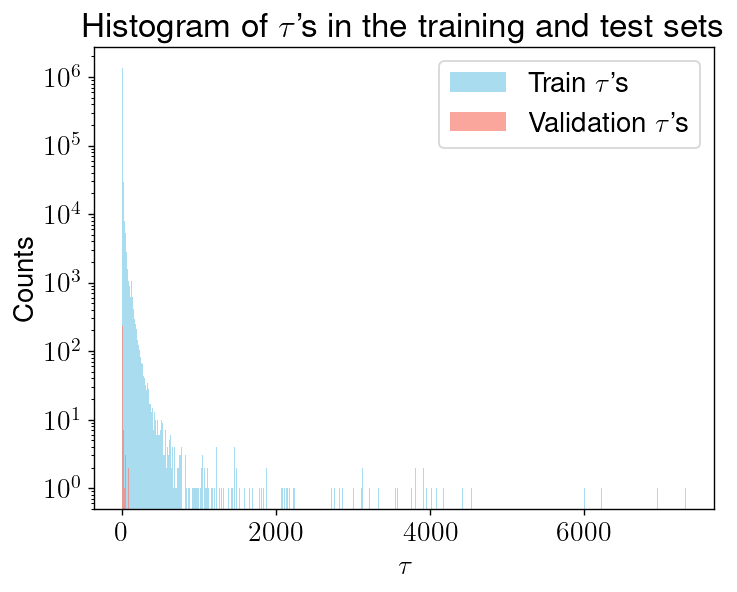

In [4]:
data = [X_train.flatten(), X_val.flatten()]
plt.hist(data[0], bins=1000, alpha=0.7, label=rf"Train $\tau$'s", color="skyblue")
plt.hist(data[1], bins=1000, alpha=0.7, label=rf"Validation $\tau$'s", color="salmon")
plt.xlabel(r"$\tau$")
plt.ylabel(r"Counts")
plt.yscale("log")
# plt.xscale("log")
plt.legend()
plt.title(r"Histogram of $\tau$'s in the training and test sets");

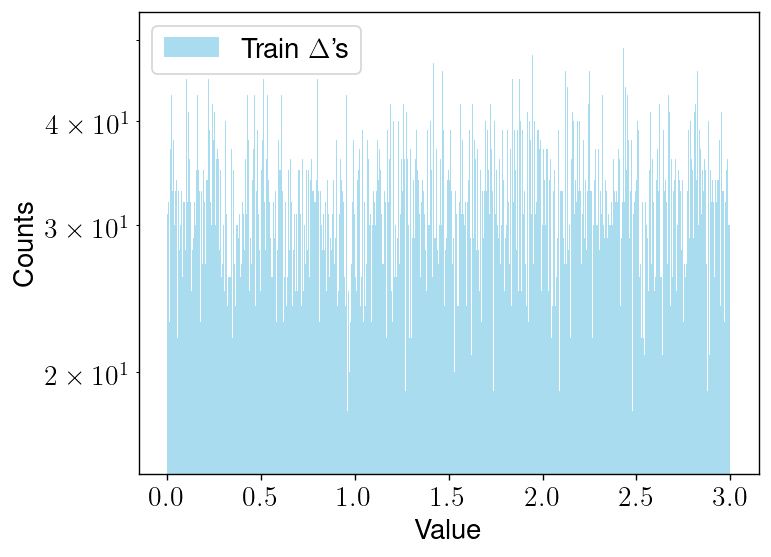

In [5]:
data = [y_train[:, 0].flatten(), y_train[:, 1].flatten()]
plt.hist(data[0], bins=1000, alpha=0.7, label=rf"Train $\Delta$'s", color="skyblue")
plt.xlabel(r"Value")
plt.ylabel("Counts")
plt.yscale("log")
# plt.xscale("log")
plt.legend();

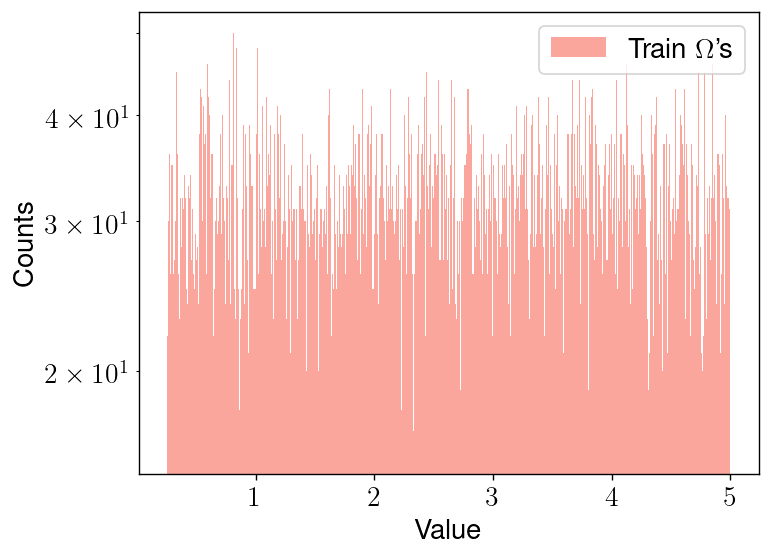

In [6]:
data = [y_train[:, 0].flatten(), y_train[:, 1].flatten()]
plt.hist(data[1], bins=1000, alpha=0.7, label=rf"Train $\Omega$'s", color="salmon")
plt.xlabel(r"Value")
plt.ylabel("Counts")
plt.yscale("log")
# plt.xscale("log")
plt.legend();
# plt.title(r"Histogram of $\Deltas$'s and $\Omega$'s in the training and test sets");

In [7]:
train_dataset = QuantumJumpDataset(
    X_train,
    y_train,
    feature_noise_std=0,
    label_noise_std=0,
    seed=42
)
val_dataset = QuantumJumpDataset(
    X_val,
    y_val,
    feature_noise_std=0,
    label_noise_std=0,
    seed=42
)

In [ ]:
num_bins = 300
hidden_dims = [128, 64, 32, 16]
num_models = 10

models = [
    EnsembleComponent(
        num_bins=num_bins,
        max_val=100,
        min_val=0,
        init_sigma=0.1,
        hidden_dims=hidden_dims,
        output_dim=2, # 2D parameter estimation problem
        activation=nn.ReLU,
        dropout=0.0
    )
    for _ in range(num_models)
]

ensemble = DeepEnsemble(models=models)

In [ ]:
lr = 0.001
num_epochs = 100
batch_size = 1000
beta1 = 0.9
beta2 = 0.999
adversarial = False
device = 'cuda'

trainer = DeepEnsembleTrainer(
    ensemble_model=ensemble,
    lr=lr,
    weight_decay=0,
    num_epochs=num_epochs,
    batch_size=batch_size,
    beta1=beta1,
    beta2=beta2,
    loss_fn=nn.GaussianNLLLoss,
    val_metric_type=LossType["rmse"],
    device=device,
    use_adversarial=adversarial
)

In [ ]:
mlflow.set_experiment("Deep Ensemble - 2D")

Traceback (most recent call last):
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 356, in search_experiments
    exp = self._get_experiment(exp_id, view_type)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 454, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 1595, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 1588, in _read_helper
    result = read_yaml(root, file_name)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/utils/yaml_utils.py", line 107, in read_yaml
    raise MissingConfigException(f"Yaml file '{file_path}' does not exist.")
mlflow.exceptions.MissingCon

<Experiment: artifact_location='file:///home/amanuelant/ensemble-param-est/mlruns/673398759472469537', creation_time=1772584555457, experiment_id='673398759472469537', last_update_time=1772584555457, lifecycle_stage='active', name='Deep Ensemble - 2D', tags={}>

In [ ]:
with mlflow.start_run() as ensemble_run:

    mlflow.log_param("batch_size", batch_size)
    mlflow.log_param("device", device)
    mlflow.log_param("lr", lr)
    mlflow.log_param("beta1", beta1)
    mlflow.log_param("beta2", beta2)
    mlflow.log_param("num_epochs", num_epochs)
    mlflow.log_param("num_bins", num_bins)
    mlflow.log_param("adversarial", adversarial)

    trainer.train(
            train_dataset=train_dataset, val_dataset=val_dataset, epochs_per_val=num_epochs-1
        )
    
    mlflow.pytorch.log_model(
        ensemble,
        name="ensemble_model",
        signature=infer_signature(train_dataset[0][0].numpy()),
    )

    run_id = ensemble_run.info.run_id
    model_uri = f"runs:/{run_id}/ensemble_model"

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Loading model with uri: {model_uri}")

selected_model = mlflow.pytorch.load_model(model_uri=model_uri)
selected_model = selected_model.to(device)

Loading model with uri: runs:/959ca42cace845fa843874097958fd89/ensemble_model


In [ ]:
X_test = np.load("../test-trajectories/2D-delta-omega/validation-trajectories-2D-delta-omega-nsets-10000.npy", mmap_mode="r")
y_test = np.load("../test-trajectories/2D-delta-omega/validation-deltas-2D-delta-omega-nsets-10000.npy")

print(f"Test data (trajectories) shape: {X_test.shape}")
print(f"Test labels shape: {y_test.shape}")

Test data (trajectories) shape: (1600, 10000, 48)
Test labels shape: (1600, 2)


In [ ]:
# NOTE: Just remaking the error computation loop bc `compute_test_error` was made with only 1D estimation in mind....
with torch.no_grad():
    rmses = []
    error_fn = RMSELoss()
    # loop over all 1,600 detuning-rabi freq pairs
    for i in tqdm(range(1600)):
        batch_of_trajs = torch.tensor(X_test[i]).to(device=device, dtype=torch.float32)
        batch_means, batch_vars = selected_model(batch_of_trajs)
        label = torch.tensor(y_test[i]).to(device=device, dtype=torch.float32)

        repeated_labels = label.repeat(batch_means.shape[0], 1)

        error = error_fn(batch_means, repeated_labels)
        rmses.append(error.cpu().numpy())

100%|██████████| 1600/1600 [04:31<00:00,  5.89it/s]


In [ ]:
bayes_preds = [
    np.load(
        f"../results_cache/results_cache/bayesian_estimation/2D/estimationBayes2DUltranest/uniform_2d_predictions_{i}.npy"
    )
    for i in range(10)
]


# Number of parameter pairs that were simulated for validation
nparams = 1600

# Number of trajectories that were simulated per parameter pair
nsets = 10000

# Number of batches in which the trajectories were divided 
nbatches = 10

# Number of trajectories per batch that correspond to a specific parameter pair
traj_per_param_pair = int(nsets/nbatches)

In [ ]:
def select_prediction_param(i_param:int, pred_list_from_batch: list, traj_per_param_pair:int):
    '''
    Giving the list of predictions from a single batch, this function selects those corresponding to trajectories that were generated from a
    specific parameter pair, indexed by "i_param". This pair corresponds to the true value of the parameters, while this function will output the corresponding predictions.
    The number of predictions selected is given by "traj_per_param_pair".

    Parameters
    ----------
    i_param (int): Index characterizing the parameter-pair (Delta,Omega) of the trajectories to be analized.
    pred_list_from_batch (list): Full list of predictions from a single batch of data
    traj_per_param_pair (int): Number of trajectories corresponding to a single parameter-pair in each batch

    Returns
    ----------
    List of predictions corresponding only to the trajectories obtained from the parameter-pair with index "i_param"
    '''
    return list(pred_list_from_batch[(i_param)*traj_per_param_pair:(i_param+1)*traj_per_param_pair])

In [ ]:
MSE_Bayes2D = []
paramlist = y_test
prediction_list = bayes_preds
# Compute the covariance matrix

for i_param in tqdm(range(nparams)): # Loop over parameter-pairs

    delta=paramlist[i_param][0]
    omega = paramlist[i_param][1]
    params = np.array(paramlist[i_param])

    deltas_pred_mean_ALL = []
    omega_pred_mean_ALL = []

    for idx_batch in range(nbatches):
        omega_preds_mean, delta_preds_mean = prediction_list[idx_batch]
        
        deltas_pred_mean_ALL+=select_prediction_param(i_param, delta_preds_mean, traj_per_param_pair)
        omega_pred_mean_ALL+=select_prediction_param(i_param, omega_preds_mean, traj_per_param_pair)

    diff_delta=(deltas_pred_mean_ALL-params[0])
    diff_omega=(omega_pred_mean_ALL-params[1])
    
    MSE = np.mean(diff_delta**2) + np.mean(diff_omega**2)
    MSE_Bayes2D.append(MSE)

MSE_Bayes2D = np.asarray(MSE_Bayes2D)
rmses_bayes = np.sqrt(MSE_Bayes2D)

100%|██████████| 1600/1600 [00:02<00:00, 689.13it/s]


In [ ]:
max_rmse = max( max(rmses), max(rmses_bayes) )
min_rmse = min( min(rmses), min(rmses_bayes) )

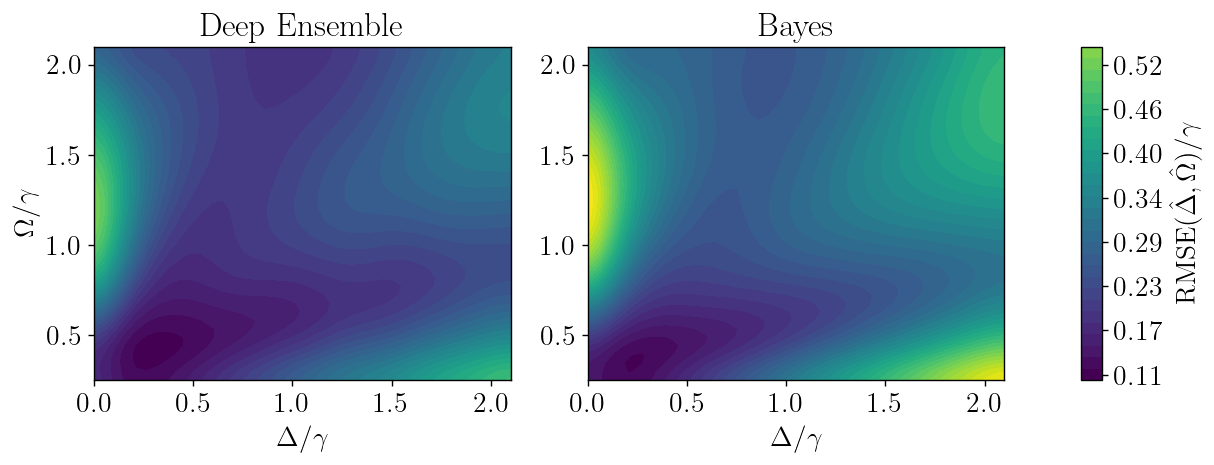

In [ ]:
x = np.sort(np.unique(y_test[:, 0]))
y = np.sort(np.unique(y_test[:, 1]))
X, Y = np.meshgrid(x, y)
levels = 40

Z1 = gaussian_filter(np.array(rmses).reshape(40, 40), sigma=2)
Z2 = gaussian_filter(np.array(rmses_bayes).reshape(40, 40), sigma=2)

vmin = min(Z1.min(), Z2.min())
vmax = max(Z1.max(), Z2.max())

cmap = plt.get_cmap("viridis")#plt.get_cmap("BuPu").reversed()
norm = matplotlib.colors.Normalize(vmin=vmin, vmax=vmax)
ticks = np.arange(0, 1.0, 0.05)

fig = plt.figure(figsize=(10,4))
gs = fig.add_gridspec(1, 3, width_ratios=[1,1,0.05])

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1], sharex=ax1, sharey=ax1)
cax = fig.add_subplot(gs[2])  # dedicated colorbar axis

cs1 = ax1.contourf(X, Y, Z1, levels=levels, cmap=cmap, norm=norm)
ax1.set_xlabel(r"$\Delta/\gamma$")
ax1.set_ylabel(r"$\Omega/\gamma$")
ax1.set_title(r"\textrm{Deep Ensemble}")

cs2 = ax2.contourf(X, Y, Z2, levels=levels, cmap=cmap, norm=norm)
ax2.set_xlabel(r"$\Delta/\gamma$")
ax2.set_title(r"\textrm{Bayes}")
ticks = np.linspace(vmin, vmax, 10)
cbar = fig.colorbar(cs1, cax=cax, ticks=ticks)
cbar.ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, pos: rf"${x:.2f}$"))
cbar.set_label(r"$\textrm{RMSE}(\hat{\Delta}, \hat{\Omega})/\gamma$")

plt.tight_layout()
# plt.savefig("figures/2D_rmse.png", dpi=300);

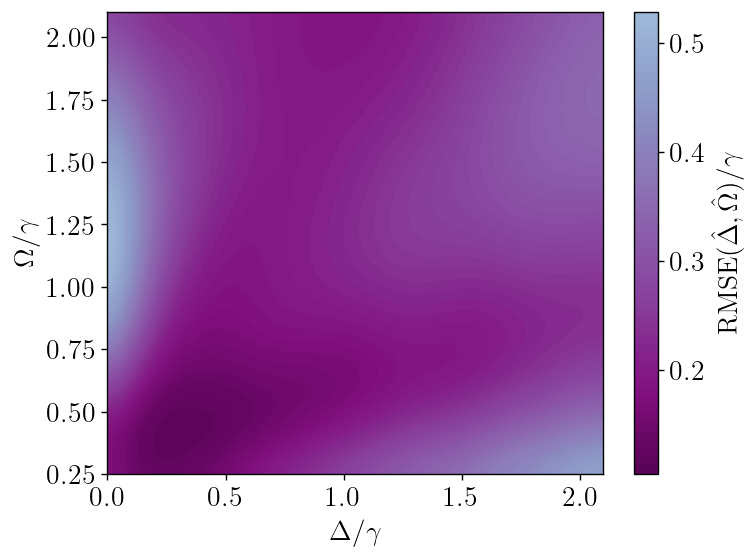

In [ ]:
x = np.sort(np.unique(y_test[:, 0])) # x axis is delta  #np.linspace(-3, 3, 200)
y = np.sort(np.unique(y_test[:, 1])) # y axis is omega #np.linspace(-3, 3, 200)
X, Y = np.meshgrid(x, y)
Z = np.array(rmses).reshape(40, 40) # there are 40x40=1,600 labels (detuning-rabi freq pairs)
Z = gaussian_filter(Z, sigma=2)

vmin = min_rmse
vmax = max_rmse
cmap = plt.get_cmap('BuPu').reversed()
ticks = [0.1, 0.2, 0.3, 0.4, 0.5]
norm = matplotlib.colors.Normalize(vmin=vmin, vmax=vmax)

# plt.figure()
cs = plt.contourf(
    X, Y, Z,
    levels=60,
    cmap=cmap,
    vmax=vmax,
    vmin=vmin,
    norm=norm
)
plt.colorbar(cs, label=r"$\textrm{RMSE}(\hat{\Delta}, \hat{\Omega})/\gamma$", ticks=ticks)
plt.xlabel(r"$\Delta/\gamma$")
plt.ylabel(r"$\Omega/\gamma$")
plt.show();


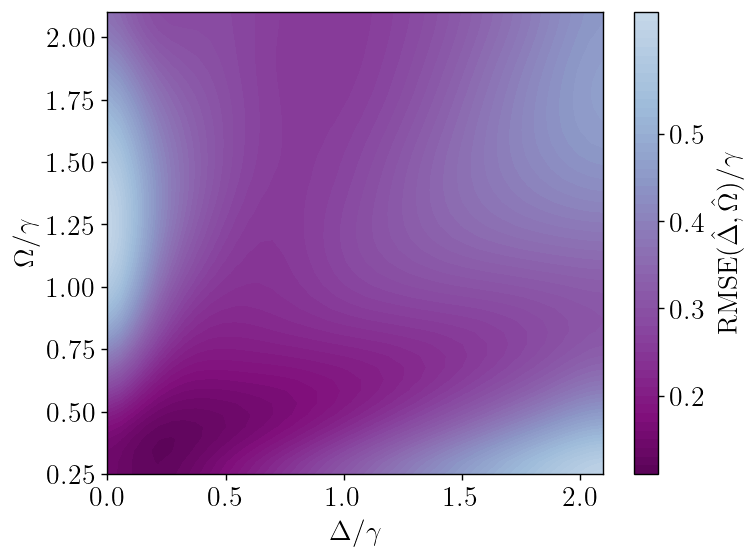

In [ ]:
x = np.sort(np.unique(y_test[:, 0])) # x axis is delta  #np.linspace(-3, 3, 200)
y = np.sort(np.unique(y_test[:, 1])) # y axis is omega #np.linspace(-3, 3, 200)
X, Y = np.meshgrid(x, y)
Z = np.array(rmses_bayes).reshape(40, 40) # there are 40x40=1,600 labels (detuning-rabi freq pairs)
Z = gaussian_filter(Z, sigma=2)

# vmin = 0.1
# vmax = 0.4
cmap = plt.get_cmap('BuPu').reversed()
# ticks = [0.1, 0.2, 0.3, 0.4, 0.5]
norm = matplotlib.colors.Normalize(vmin=vmin, vmax=vmax)

# plt.figure()
cs = plt.contourf(
    X, Y, Z,
    levels=60,
    cmap=cmap,
    vmax=vmax,
    vmin=vmin,
    norm=norm
)
plt.colorbar(cs, label=r"$\textrm{RMSE}(\hat{\Delta}, \hat{\Omega})/\gamma$", ticks=ticks)
plt.xlabel(r"$\Delta/\gamma$")
plt.ylabel(r"$\Omega/\gamma$")
plt.show();


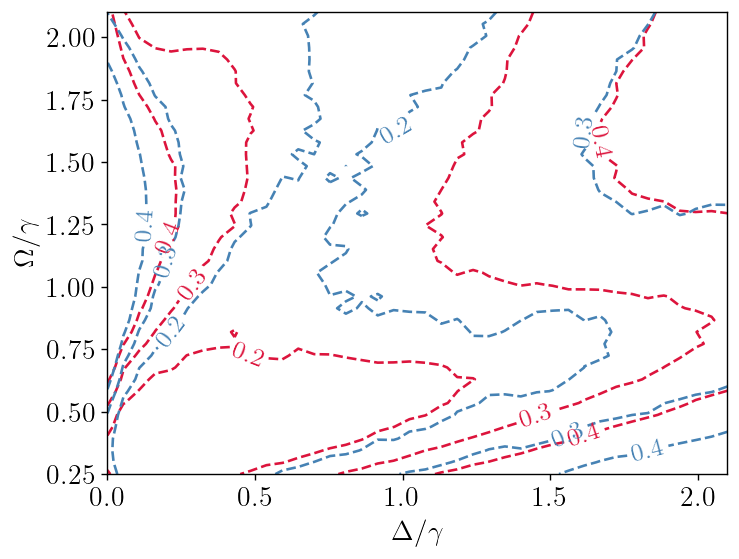

In [ ]:
cmap = plt.get_cmap('BuPu').reversed()
# ticks = [0.1, 0.2, 0.3, 0.4, 0.5]
norm = matplotlib.colors.Normalize(vmin=vmin, vmax=vmax)

plt.figure()
cs = plt.contour(
    X, Y, np.array(rmses_bayes).reshape(40, 40),
    levels=[0.2,0.3,0.4],
    colors='crimson',
    linestyles = 'dashed'
)
plt.clabel(cs, inline=True, fontsize=15)
cs = plt.contour(
    X, Y, np.array(rmses).reshape(40, 40),
    levels=[0.2,0.3,0.4],
    colors='steelblue',
    linestyles = 'dashed'
)
plt.clabel(cs, inline=True, fontsize=15)
plt.xlabel(r"$\Delta/\gamma$")
plt.ylabel(r"$\Omega/\gamma$")
plt.show();
